[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hehteram/CRISP/blob/main/crisp.ipynb)

# CRISP: Leveraging Privacy Noise as Side Information to Break the Privacy–Accuracy Tradeoff in Edge–Cloud Inference

<img src="https://raw.githubusercontent.com/hehteram/CRISP/main/images/fig_framework.svg"
     style="display:block; margin:auto; width:800px;">

**General CRISP Framework.** The client sends a privatized query to the server and retains noise-derived side information locally. The server processes the query and returns its response. A small client-side decoder combines this response with the side information to mitigate the noise and recover an accurate prediction.

This code is provided in a Jupyter notebook file.

Recommended Google Colab (GPU runtime enabled)

# Setup

Libraries

In [1]:
# Libraries
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torch.nn.functional as F
import torchvision
import torch.backends.cudnn as cudnn

import sys
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from torchinfo import summary


Seed

In [2]:
# Set random seed for reproducibility
manual_seed = 100
random.seed(manual_seed)
np.random.seed(manual_seed)
torch.manual_seed(manual_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(manual_seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True


Hyperparameters

In [3]:
# Hyperparameters
batch_size_train = 128
batch_size_test = 100
num_workers = 2


Connect to Drive (optional)

In [4]:
# Enable to load/save files in your own Google Drive.
try:
    from google.colab import drive
    use_drive = True
except ImportError:
    use_drive = False

if use_drive:
    from google.colab import drive
    drive.mount('/content/drive')


Device (use GPU)

In [5]:
# device
use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
print ('Your system: ' + str(device))

Your system: cuda


Save and Load

In [6]:
# Path of saving
save_path = Path('/content/drive/MyDrive/crisp') if use_drive else Path('crisp')

# Save function
def mysave(state, name):
    save_path.mkdir(parents=True, exist_ok=True)
    path = save_path / f'{name}.pth'
    torch.save(state, path)
    print(f'Saved: {path}')

# Load function
def myload(name):
    return torch.load(save_path / f'{name}.pth', map_location=device, weights_only=True)


# Test
mysave(state='It is a test!', name='test')
state = myload(name='test')
print(state)


Saved: crisp/test.pth
It is a test!


Helper functions for deep learning

In [7]:
# Train function
def train_function(trainloader, model, optimizer, criterion, accuracymeasure):
    global mymode
    mymode = 'train'

    loss_sum = 0
    acc_sum = 0
    sample_num = 0

    model.train()
    for images, targets in trainloader:
        # Data
        images, targets = images.to(device), targets.to(device)
        # Forward
        outputs = model(images)
        loss = criterion(outputs, targets)
        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # Track
        sample_num += images.size(0)
        loss_sum += loss.item() * images.size(0)
        acc_sum += accuracymeasure(outputs, targets).item() * images.size(0)

    # Result
    avg_loss = float(loss_sum) / float(sample_num)
    avg_acc = float(acc_sum) / float(sample_num) * 100.0

    return avg_loss, avg_acc

# Test function
def test_function(testloader, model, criterion, accuracymeasure):
    global mymode
    mymode = 'test'

    loss_sum = 0
    acc_sum = 0
    sample_num = 0

    model.eval()
    with torch.no_grad():
        for images, targets in testloader:
            # Data
            images, targets = images.to(device), targets.to(device)
            # Forward
            outputs = model(images)
            # Track
            sample_num += images.size(0)
            loss_sum += criterion(outputs, targets).item() * images.size(0)
            acc_sum += accuracymeasure(outputs, targets).item() * images.size(0)

    # Result
    avg_loss = float(loss_sum) / float(sample_num)
    avg_acc = float(acc_sum) / float(sample_num) * 100.0

    return avg_loss, avg_acc

# Run function
def run(track, trainloader, testloader, model, optimizer, criterion, accuracymeasure, epoch_num, printidx=1):
    # Trackers
    track = {'loss_train':[], 'acc_train':[], 'loss_test':[], 'acc_test':[]} if track == None else track

    for epoch in range(0, epoch_num):
        # Train & Test
        loss_train, acc_train = train_function(trainloader, model, optimizer, criterion, accuracymeasure)
        loss_test, acc_test = test_function(testloader, model, criterion, accuracymeasure)

        # Track
        track['loss_train'].append(loss_train)
        track['acc_train'].append(acc_train)
        track['loss_test'].append(loss_test)
        track['acc_test'].append(acc_test)
        if epoch % printidx == 0: print(f'Epoch [{epoch+1}/{epoch_num}] | Loss -> Test {loss_test:.4f} Train {loss_train:.4f} | Acc -> Test {acc_test:.3f} Train {acc_train:.3f} |')

    return track

# Visualisation function
def vis_tensor(tensor, ch=0, allkernels=False, nrow=8, padding=1, scale=2):
    # Adapted from https://stackoverflow.com/questions/55594969/how-to-visualise-filters-in-a-cnn-with-pytorch

    if not isinstance(tensor, np.ndarray): tensor = tensor.detach().clone().cpu().numpy()
    tensor = tensor.copy()
    n,c,h,w = tensor.shape
    if allkernels: tensor = tensor.reshape(n*c, -1, h, w)
    elif c != 3: tensor = tensor[:, ch:ch + 1, :, :]
    tensor = tensor.transpose(0, 2, 3, 1)
    n,h,w,c = tensor.shape

    rows = int(np.ceil(n / nrow))
    clms = n if n <= nrow else nrow
    grid = np.zeros(shape=(padding + rows * (h + padding), padding + clms * (w + padding), c), dtype=np.uint8)
    for i in range(n):
        im = tensor[i]
        im -= im.min(); im /= (im.max() + 1e-12); im *= 255; im = im.astype(np.uint8) # Normalize
        x = i % clms
        y = i // clms
        grid[padding + y * (h + padding): h + padding + y * (h + padding), padding + x * (w + padding): w + padding + x * (w + padding)] = im
    if not n == rows * clms: grid[padding + y * (h + padding):, padding + (x + 1) * (w + padding): ] = 255
    plt.figure( figsize=(nrow*scale,rows*scale) )
    plt.imshow(grid.squeeze(-1), cmap='gray') if c == 1 else plt.imshow(grid)

    plt.axis('off')
    plt.ioff()
    plt.show()

# Dataset

MNIST

MNIST: train=60000, test=10000, input=(1,32,32)


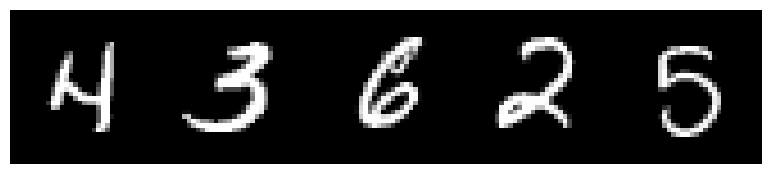

In [8]:
# Transforms
transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.1307,), std=(0.3040,)),
])

# Datasets and loaders
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size_train, shuffle=True, num_workers=num_workers, drop_last=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size_test, shuffle=False,num_workers=num_workers, drop_last=False)

# Show
print(f'MNIST: train={len(trainset)}, test={len(testset)}, input=(1,32,32)')
images, _ = next(iter(trainloader))
vis_tensor(images[:5])


Normalization

In [9]:
def Normalized(x):
    mean = torch.mean(x, dim=[1, 2, 3], keepdim=True)
    std = torch.std(x, dim=[1, 2, 3], keepdim=True)
    x = (x - mean.detach()) / (std.detach() + 1e-8)
    return x

Mixup

In [10]:
class MixupGenerator:
    def __init__(self, dataloader):
        self.dataloader = dataloader
        self.iter_dataloader = iter(self.dataloader)

    def mixup_gen(self, K_mixup, num_sample, pre_function):
        img, ـ = next(self.iter_dataloader)
        img = img.to(device)
        img = Normalized(pre_function(img))
        if img.size(0) < num_sample: raise StopIteration

        img_size = img.size()
        img = img.view(img.size(0), -1)

        img_mix = torch.zeros_like(img)
        for ـ in range(K_mixup - 1):
            indxs = list(range(img.size(0)))
            np.random.shuffle(indxs)
            img_mix += img[indxs]
        img_mix = img_mix.view(img_size)

        return img_mix[0:num_sample]

    def sample(self, K_mixup, num_sample, pre_function=lambda x: x, sample_size=None):
        """
        Generates `num_sample` mixup samples that are mixtures of `K_mixup - 1` samples from the dataloader.

        Each mixup sample is computed as:
        img_mix = Normalized(pre_function(img_1)) + ... + Normalized(pre_function(img_{K_mixup - 1})),
        where img_i is a sample from the dataloader.
        """

        try:
            img_mix = self.mixup_gen(K_mixup, num_sample, pre_function)
        except StopIteration:
            self.iter_dataloader = iter(self.dataloader)
            img_mix = self.mixup_gen(K_mixup, num_sample, pre_function)

        return img_mix

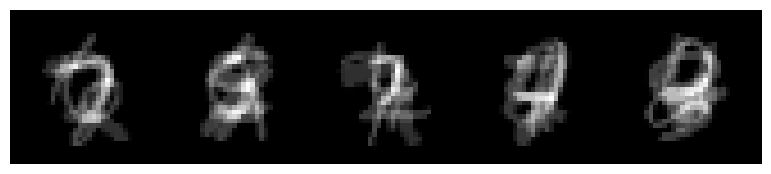

In [11]:
# Make mixup generator
trainloader_new = torch.utils.data.DataLoader(trainset, batch_size=batch_size_train, shuffle=True, num_workers=2, drop_last=True)
testloader_new = torch.utils.data.DataLoader(testset, batch_size=batch_size_test, shuffle=True, num_workers=2, drop_last=False)

mixup_generator_train = MixupGenerator(trainloader_new)
mixup_generator_test = MixupGenerator(testloader_new)

# Show
img = mixup_generator_train.sample(K_mixup=5, num_sample=10, pre_function=lambda x: x, sample_size=None)
vis_tensor(img[0:5])

Gaussian

In [12]:
class GaussianGenerator:
    def __init__(self,):
        pass

    def sample(self, Sigma_gaussian, num_sample, pre_function=None, sample_size=[3, 224, 224]):
        """ Generates `num_sample` Gaussian samples with std of Sigma_gaussian. """

        return Sigma_gaussian * torch.randn([num_sample] + sample_size, device=device)

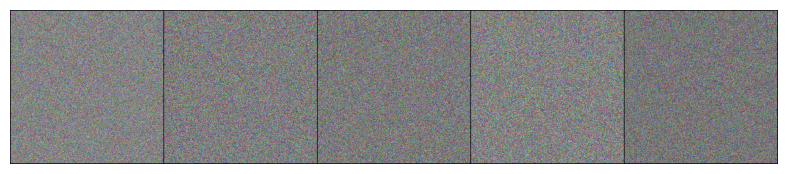

In [13]:
# Make gaussian generator
gaussian_generator_train = GaussianGenerator()
gaussian_generator_test = GaussianGenerator()

# Show
img = gaussian_generator_train.sample(Sigma_gaussian=5, num_sample=10, pre_function=None, sample_size=[3, 224, 224])
vis_tensor(img[0:5])

Noise generator

In [14]:
def get_noise_generator(mechanism, mymode):
    if mechanism == 'gaussian' and mymode == 'train':
        return gaussian_generator_train
    elif mechanism == 'gaussian' and mymode == 'test':
        return gaussian_generator_test
    elif mechanism == 'mixup' and mymode == 'train':
        return mixup_generator_train
    elif mechanism == 'mixup' and mymode == 'test':
        return mixup_generator_test
    else:
        raise ValueError(f'Invalid mechanism: {mechanism} or mymode: {mymode}')

# Privacy-Accuracy Trade-Off

## Deep learning setup

Network architecture

In [15]:
# ResNet18
# Adapted from https://github.com/kuangliu/pytorch-cifar/blob/master/models/resnet.py
# Copyright (c) 2017 liukuang. MIT License (linked above).

class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, 1, stride=stride, bias=False),
                nn.BatchNorm2d(planes),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class ResNet(nn.Module):
    def __init__(self, num_channels=1, num_classes=64):
        super().__init__()
        self.in_planes = 64
        self.conv1 = nn.Conv2d(num_channels, 64, 3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.layer1 = self._make_layer(64, 2, 1)
        self.layer2 = self._make_layer(128, 2, 2)
        self.layer3 = self._make_layer(256, 2, 2)
        self.layer4 = self._make_layer(512, 2, 2)
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, planes, count, stride):
        layers = []
        for current_stride in [stride] + [1] * (count - 1):
            layers.append(BasicBlock(self.in_planes, planes, current_stride))
            self.in_planes = planes
        return nn.Sequential(*layers)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer4(self.layer3(self.layer2(self.layer1(out))))
        return self.fc(F.avg_pool2d(out, 4).flatten(1))




class ResNet18(nn.Module):
    def __init__(self, num_channels=1, num_classes=64):
        super().__init__()
        self.model = ResNet(num_channels=num_channels, num_classes=num_classes)

    def forward(self, x):
        return self.model(x)


In [16]:
# ---------------- Client ---------------- #
class Client_g_Pre(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return x


class Client_g_Post(nn.Module):
    def __init__(self):
        super().__init__()
        self.b1 = nn.BatchNorm1d(64)
        self.fc1 = nn.Linear(64, 10)

    def forward(self, x):
        return self.fc1(F.relu(self.b1(x)))


# ---------------- Server ---------------- #
class Server_f(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = ResNet18(num_channels=1, num_classes=64)

    def forward(self, x):
        return self.model(x)


# ---------------- Offline ---------------- #
class Offline_g_Z(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv2d1 = nn.Conv2d(1, 2, kernel_size=5, stride=3, padding=0)
        self.b1 = nn.BatchNorm2d(2)
        self.fc1 = nn.Linear(2 * 10 * 10, 64)

    def forward(self, x):
        out = F.relu(self.b1(self.conv2d1(x)))
        return self.fc1(out.flatten(1))


# ---------------- Network ---------------- #
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        # Offline
        self.offline_g_Z = Offline_g_Z()
        # Client - preprocessing
        self.client_g_Pre = Client_g_Pre()
        # Server
        self.server_f = Server_f()
        # client - postprocessing
        self.client_g_Post = Client_g_Post()


    def forward(self, x):
        # Client - preprocessing
        u = self.client_g_Pre(x)

        # Offline - noise
        noise_generator = get_noise_generator(mechanism=mechanism, mymode=mymode)
        z_Pre = noise_generator.sample(Z_scale, num_sample=u.size(0), pre_function=self.client_g_Pre, sample_size=list(u.size()[1:]))
        z_Post = self.offline_g_Z(z_Pre)

        # Client - query
        q = Normalized(u) + z_Pre

        # Server - answer
        a = self.server_f(Normalized(q))

        # Client - postprocessing
        out = self.client_g_Post(a + z_Post)

        return out


Network costs

In [17]:
# Set models_list (Class, input_size)
models_list = [
    (Client_g_Pre(), (1, 1, 32, 32)),
    (Client_g_Post(), (1, 64)),
    (Server_f(), (1, 1, 32, 32)),
    (Offline_g_Z(), (1, 1, 32, 32)),
]

# Eval
table = {}
for model, input_size in models_list:
    model_name = type(model).__name__
    table[model_name] = {}
    print(f'{model_name} -----------')
    result = summary(model, input_size=input_size, mode="eval")
    # print(result)
    print(f"Total Parameters: {result.total_params}")
    print(f"Total FLOPs: {result.total_mult_adds}")
    table[model_name]['Params'] = result.total_params
    table[model_name]['FLOPs'] = result.total_mult_adds
    print('\n')

# Result
# print(table)

Client_g_Pre -----------
Total Parameters: 0
Total FLOPs: 0


Client_g_Post -----------
Total Parameters: 778
Total FLOPs: 778


Server_f -----------
Total Parameters: 11200512
Total FLOPs: 554280384


Offline_g_Z -----------
Total Parameters: 12920
Total FLOPs: 18068




Deep learning setup

In [18]:
# -------------------------------------------------------
# Model
# -------------------------------------------------------
model = Network().to(device)

# -------------------------------------------------------
# Criterion
# -------------------------------------------------------
criterion_CE = nn.CrossEntropyLoss()

def criterion_SingleLabel(outputs, targets):
    return criterion_CE(outputs, targets.long())

criterion = criterion_SingleLabel

# -------------------------------------------------------
# Accuracy measure
# -------------------------------------------------------
def accuracymeasure_SingleLabel(outputs, targets):
    predicted_labels = torch.max(outputs.data, 1)[1]
    return (predicted_labels == targets).sum() / targets.size(0)

accuracymeasure = accuracymeasure_SingleLabel

# -------------------------------------------------------
# Optimizer
# -------------------------------------------------------
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# -------------------------------------------------------
# Global variables
# -------------------------------------------------------
mymode = None
track = None


## Run

Parameters

In [19]:
# Mixup: Z_scale is K (client image plus K-1 noise images).
# Gaussian: Z_scale is the noise standard deviation.
mechanism = 'mixup'
Z_scale = 16

if mechanism == 'mixup' and (type(Z_scale) is not int or Z_scale < 1):
    raise ValueError('Mixup K must be a positive integer.')
if mechanism not in ('mixup', 'gaussian') or Z_scale < 0:
    raise ValueError('Choose mixup or gaussian with a valid noise parameter.')


Train model (optional)

In [20]:
# Disabled for the pretrained evaluation demonstration.
train_model = False
if train_model:

    # Run
    epoch_num = 1400
    track = run(track, trainloader, testloader, model, optimizer, criterion, accuracymeasure, epoch_num, printidx=1)

    # Save
    mysave(state=model.state_dict(), name=f'model_{mechanism}_{Z_scale}')


Load pretrained model and evaluate

For CRISP over MNIST-Mixup-`K = 16` use Hugging Face filename: `models/model_mixup_16.pth` in `hehteram/CRISP`


In [21]:
# Load model
assert mechanism == 'mixup' and Z_scale == 16
path = hf_hub_download(
    repo_id='hehteram/CRISP',
    filename=f'models/model_mixup_16.pth',
)
model.load_state_dict(torch.load(path, map_location=device, weights_only=True), strict=True)

# Test
loss_test, acc_test = test_function(testloader, model, criterion, accuracymeasure)
print(f'MNIST | {mechanism} | {Z_scale} | accuracy={acc_test:.3f}%')

MNIST | mixup | 16 | accuracy=97.160%
